# **Exploratory Data Analysis**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
# load datafile 
ai_df = pd.read_csv("ai_student_impact_cleaned.csv")
# read the first five rows
ai_df.head()

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium


In [3]:
ai_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  50000 non-null  int64  
 1   Major_Category              50000 non-null  object 
 2   Year_of_Study               50000 non-null  object 
 3   Pre_Semester_GPA            50000 non-null  float64
 4   Weekly_GenAI_Hours          50000 non-null  float64
 5   Primary_Use_Case            50000 non-null  object 
 6   Prompt_Engineering_Skill    50000 non-null  object 
 7   Tool_Diversity              50000 non-null  int64  
 8   Paid_Subscription           50000 non-null  bool   
 9   Traditional_Study_Hours     50000 non-null  float64
 10  Perceived_AI_Dependency     50000 non-null  int64  
 11  Institutional_Policy        50000 non-null  object 
 12  Anxiety_Level_During_Exams  50000 non-null  int64  
 13  Post_Semester_GPA           500

##### **Business Question 1:** Does using AI more frequently affect students' academic performance?

In [4]:
ai_df[['Weekly_GenAI_Hours', 'Post_Semester_GPA']].corr()

,Weekly_GenAI_Hours,Post_Semester_GPA
Weekly_GenAI_Hours,1.0000,-0.0186
Post_Semester_GPA,-0.0186,1.0000


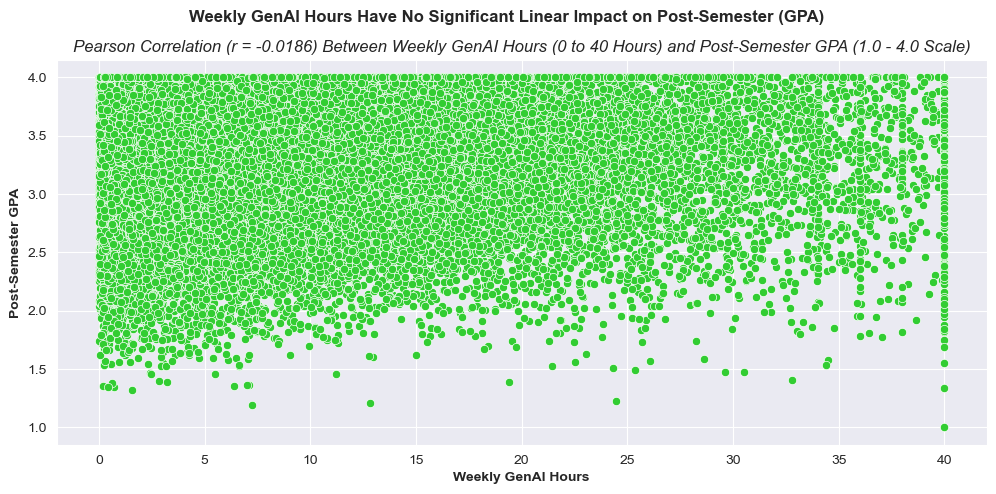

In [5]:
sns.set_style("darkgrid")
plt.figure(figsize = (12, 5))
sns.scatterplot(data = ai_df, x = "Weekly_GenAI_Hours", y = "Post_Semester_GPA", color = "limegreen")
plt.title("Pearson Correlation (r = -0.0186) Between Weekly GenAI Hours (0 to 40 Hours) and Post-Semester GPA (1.0 - 4.0 Scale)", style = "italic")
plt.suptitle("Weekly GenAI Hours Have No Significant Linear Impact on Post-Semester (GPA)", fontweight = "bold")
plt.xlabel("Weekly GenAI Hours", fontweight = "bold")
plt.ylabel("Post-Semester GPA", fontweight = "bold")
plt.show()

##### **Business Question 2:** Does AI usage reduce students' traditional study time?

In [6]:
ai_df[['Weekly_GenAI_Hours', 'Traditional_Study_Hours']].corr()

,Weekly_GenAI_Hours,Traditional_Study_Hours
Weekly_GenAI_Hours,1.000000,-0.157368
Traditional_Study_Hours,-0.157368,1.000000


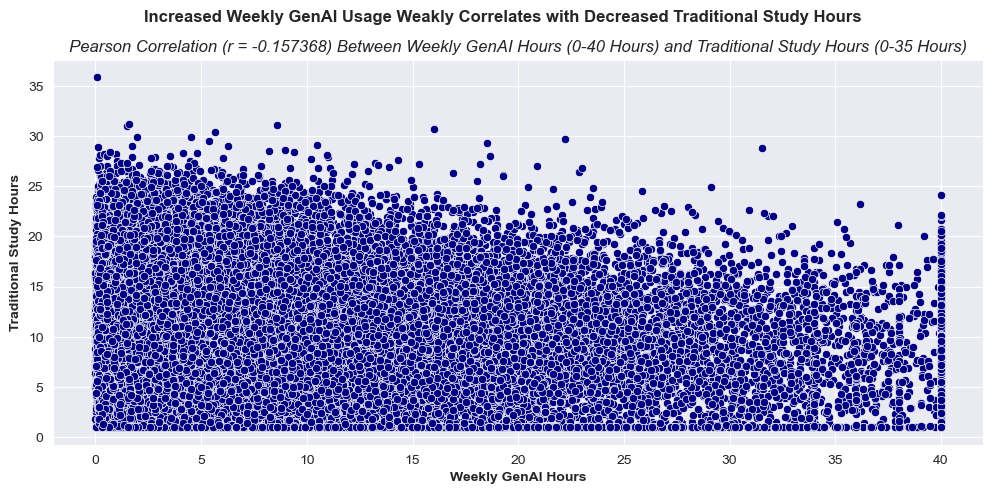

In [7]:
sns.set_style("darkgrid")
plt.figure(figsize = (12, 5))
sns.scatterplot(data = ai_df, x = "Weekly_GenAI_Hours", y = "Traditional_Study_Hours", color = "navy")
plt.title("Pearson Correlation (r = -0.157368) Between Weekly GenAI Hours (0-40 Hours) and Traditional Study Hours (0-35 Hours)", style = "italic")
plt.suptitle("Increased Weekly GenAI Usage Weakly Correlates with Decreased Traditional Study Hours", fontweight = "bold")
plt.xlabel("Weekly GenAI Hours", fontweight = "bold")
plt.ylabel("Traditional Study Hours", fontweight = "bold")
plt.show()

##### **Business Question 3:** Which academic major uses AI the most?

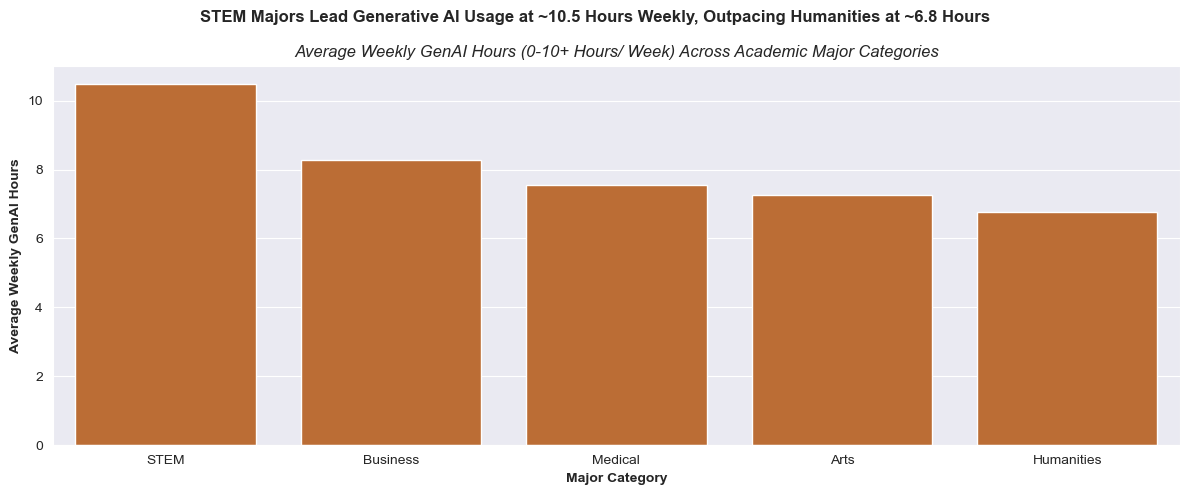

In [8]:
sns.set_style("darkgrid")
plt.figure(figsize = (12, 5))
major_avg_weekly_ai_hours = ai_df.groupby("Major_Category")["Weekly_GenAI_Hours"].mean().sort_values(ascending = False)

sns.barplot(data = major_avg_weekly_ai_hours, color = "chocolate")
plt.title("Average Weekly GenAI Hours (0-10+ Hours/ Week) Across Academic Major Categories", style = "italic")
plt.suptitle("STEM Majors Lead Generative AI Usage at ~10.5 Hours Weekly, Outpacing Humanities at ~6.8 Hours", fontweight = "bold")
plt.xlabel("Major Category", fontweight = "bold")
plt.ylabel("Average Weekly GenAI Hours", fontweight = "bold")
plt.tight_layout()
plt.show()

##### **Business Question 4:** Does AI dependency affect students' skill retention?

In [9]:
def ai_dependency_cat(data):
    if data <= 3:
        return "Low Dependency"
    elif data <= 6:
        return "Moderate Dependency"
    elif data <= 10:
        return "High Dependency"
    
ai_df["AI_Dependency"] = ai_df["Perceived_AI_Dependency"].apply(ai_dependency_cat)

ai_df.head()

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level,AI_Dependency
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High,Moderate Dependency
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low,Low Dependency
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium,Moderate Dependency
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium,Low Dependency
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium,Moderate Dependency


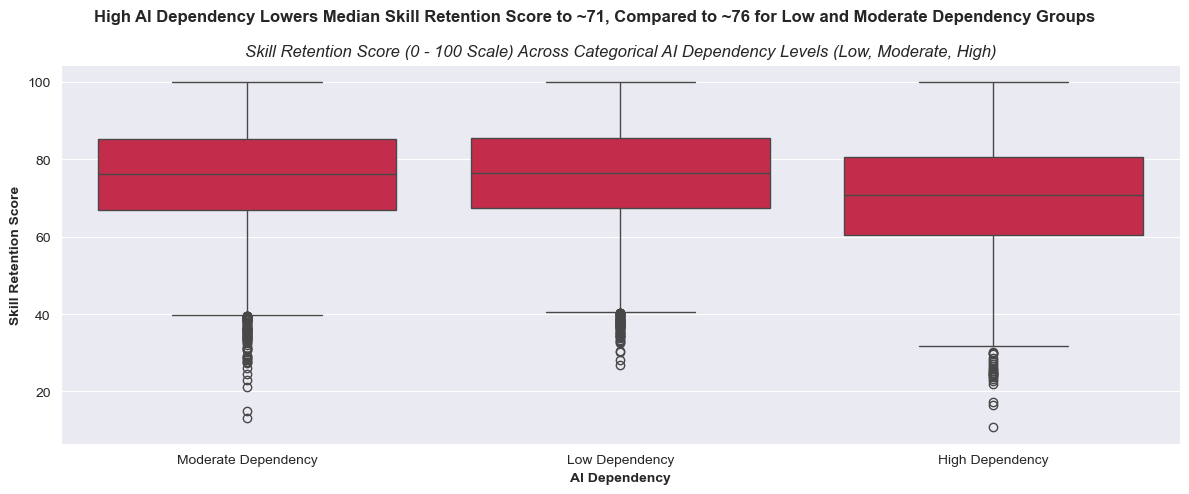

In [10]:
sns.set_style("darkgrid")
plt.figure(figsize = (12, 5))
sns.boxplot(data = ai_df, x = "AI_Dependency", y = "Skill_Retention_Score", color = "crimson")
plt.title("Skill Retention Score (0 - 100 Scale) Across Categorical AI Dependency Levels (Low, Moderate, High)", style = "italic")
plt.suptitle("High AI Dependency Lowers Median Skill Retention Score to ~71, Compared to ~76 for Low and Moderate Dependency Groups", fontweight = "bold")
plt.xlabel("AI Dependency", fontweight = "bold")
plt.ylabel("Skill Retention Score", fontweight = "bold")
plt.tight_layout()
plt.show()

##### **Business Question 5:** Which students have the highest burnout risk?

In [11]:
def ai_usage_cat(data):
    if data <= 5:
        return "Low Usage"
    elif data <= 12:
        return "Medium Usage"
    elif data > 12:
        return "High Usage"

ai_df["AI_Usage"] = ai_df["Weekly_GenAI_Hours"].apply(ai_usage_cat)

ai_df.head()

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level,AI_Dependency,AI_Usage
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High,Moderate Dependency,High Usage
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low,Low Dependency,Low Usage
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium,Moderate Dependency,High Usage
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium,Low Dependency,Low Usage
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium,Moderate Dependency,Medium Usage


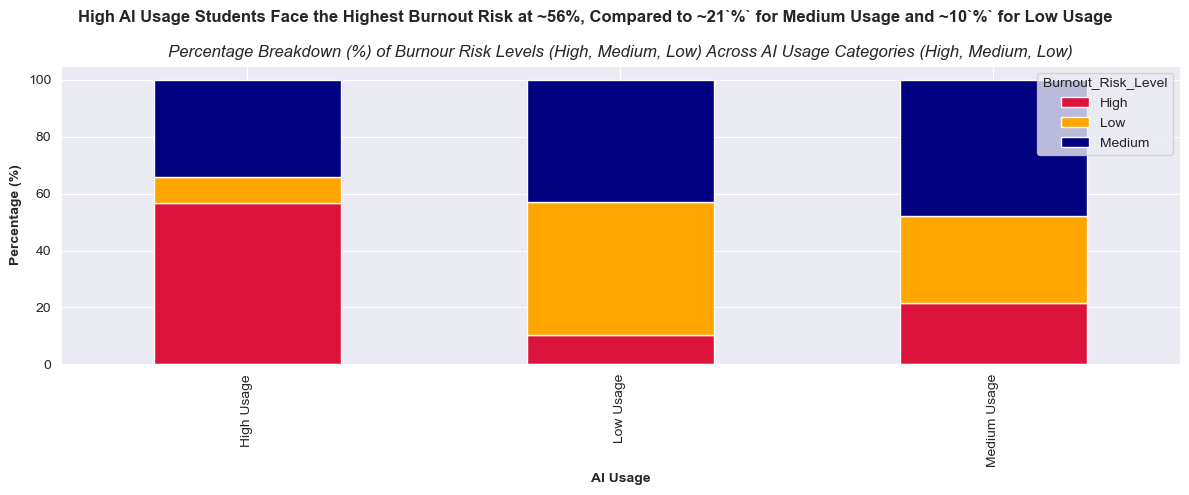

In [12]:
stacked_data = pd.crosstab(ai_df["AI_Usage"], ai_df["Burnout_Risk_Level"], normalize = 'index')*100

stacked_data.plot(kind = "bar", stacked = True, figsize = (12, 5), color = ['crimson', 'orange', 'navy'])
plt.title("Percentage Breakdown (%) of Burnour Risk Levels (High, Medium, Low) Across AI Usage Categories (High, Medium, Low)", style = "italic")
plt.suptitle("High AI Usage Students Face the Highest Burnout Risk at ~56%, Compared to ~21`%` for Medium Usage and ~10`%` for Low Usage", fontweight = "bold")
plt.xlabel("AI Usage", fontweight = "bold")
plt.ylabel("Percentage (%)", fontweight = "bold")
plt.tight_layout()
plt.show()

##### **Business Question 6:** Does prompt engineering skill influence students' academic performance?

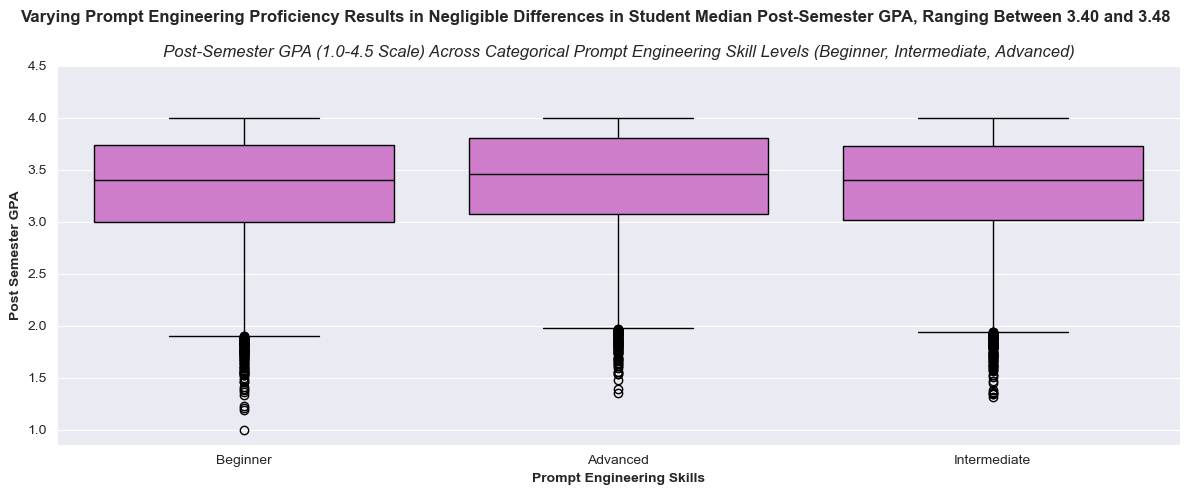

In [13]:
sns.set_style("darkgrid")
plt.figure(figsize = (12, 5))
sns.boxplot(data = ai_df, x = "Prompt_Engineering_Skill", y = "Post_Semester_GPA", color = "orchid", linecolor = "black")
plt.title("Post-Semester GPA (1.0-4.5 Scale) Across Categorical Prompt Engineering Skill Levels (Beginner, Intermediate, Advanced)", style = "italic")
plt.suptitle("Varying Prompt Engineering Proficiency Results in Negligible Differences in Student Median Post-Semester GPA, Ranging Between 3.40 and 3.48", fontweight = "bold")
plt.xlabel("Prompt Engineering Skills", fontweight = "bold")
plt.ylabel("Post Semester GPA", fontweight = "bold")
plt.tight_layout()
plt.ylim(top = 4.5)
plt.show()

##### **Business Question 7:** What are the most common purposes for which students use Generative AI?

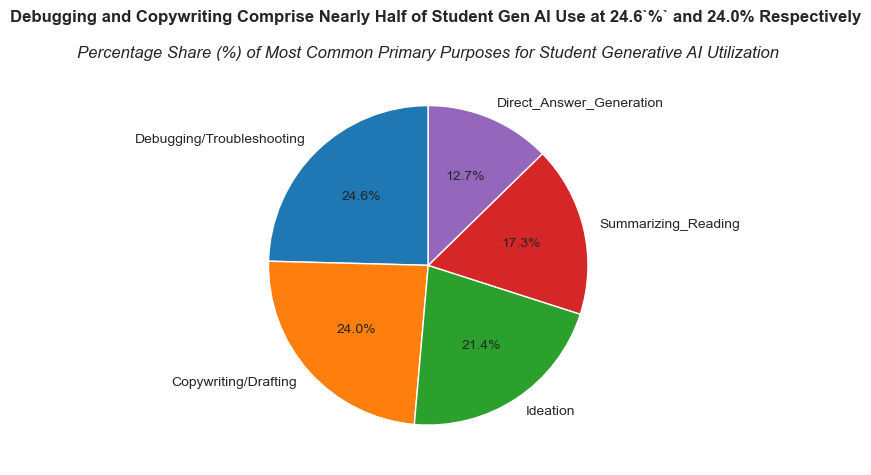

In [34]:
plt.pie(ai_df['Primary_Use_Case'].value_counts(), 
        labels = ai_df['Primary_Use_Case'].value_counts().index, 
        autopct = "%1.1f%%", 
        startangle = 90)
plt.title("Percentage Share (%) of Most Common Primary Purposes for Student Generative AI Utilization", style = "italic")
plt.suptitle("Debugging and Copywriting Comprise Nearly Half of Student Gen AI Use at 24.6`%` and 24.0% Respectively", fontweight = "bold")
plt.tight_layout()
plt.show()

##### **Business Question 8:** What is the distribution of students' post-semester GPA?

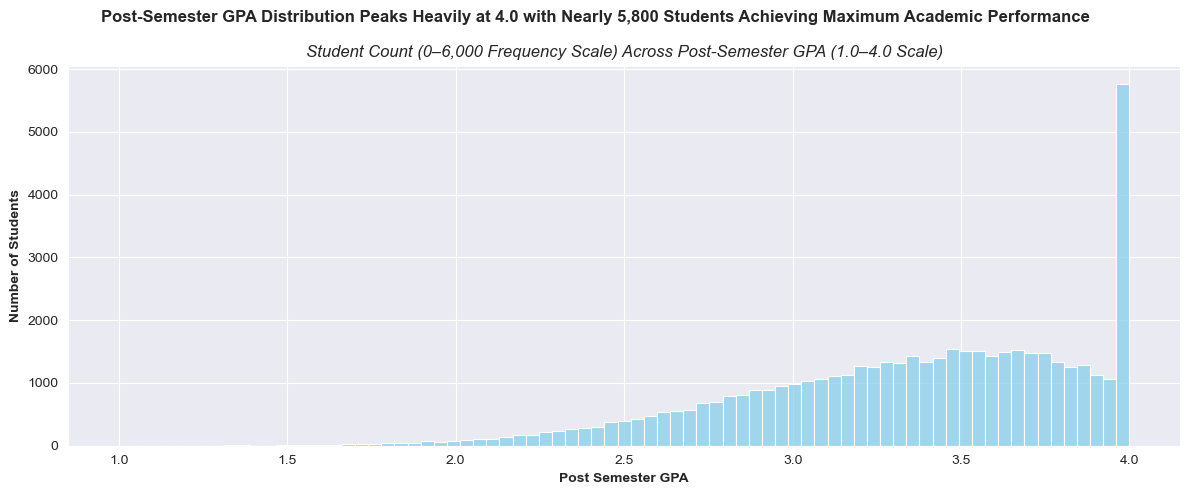

In [30]:
sns.set_style("darkgrid")
plt.figure(figsize = (12, 5))
sns.histplot(data = ai_df["Post_Semester_GPA"], color = "skyblue")
plt.title("Student Count (0–6,000 Frequency Scale) Across Post-Semester GPA (1.0–4.0 Scale)", style = "italic")
plt.suptitle("Post-Semester GPA Distribution Peaks Heavily at 4.0 with Nearly 5,800 Students Achieving Maximum Academic Performance", fontweight = "bold")
plt.xlabel("Post Semester GPA", fontweight = "bold")
plt.ylabel("Number of Students", fontweight = "bold")
plt.tight_layout()
plt.show()